# **AnimeEnhance: Anime Image Super-Resolution Pipeline (4x)**

_Anime image enhancement using pretrained Real-ESRGAN._

**Author:** Rozhak  
**Version:** 0.1.0  
**Last Updated:** 2026-11-11

---

**Description**

AnimeEnhance merupakan pipeline berbasis Python untuk merestorasi dan memperbesar resolusi gambar ilustrasi anime menggunakan model pretrained Real-ESRGAN hingga skala 4x dengan tetap mempertahankan karakteristik visual dari gambar aslinya.

## **1. Pendahuluan**

### **1.1 Latar Belakang**

Dalam produksi komik dan ilustrasi digital, materi gambar lama serta aset referensi visual kerap mengalami degradasi akibat kompresi berulang atau resolusi pemindaian yang rendah. AnimeEnhance dirancang untuk meningkatkan resolusi gambar hingga 4x menggunakan arsitektur *deep learning* Real-ESRGAN (RRDBNet 6 blok residual) pada akselerator GPU NVIDIA L4 dengan presisi `FP16`.

Pipeline ini menerapkan prinsip restorasi non-destruktif. Berkas masukan diproses secara `read-only` agar berkas asli tidak tertimpa atau terdistorsi, dengan rasio aspek (*aspect ratio*) yang dipertahankan penuh. Restorasi berfokus menjaga keaslian identitas karakter, khususnya ketajaman garis *line art*, detail rambut, dan iris mata, tanpa manipulasi bentuk wajah maupun halusinasi sintetis dari modul sekunder. Untuk menjaga efisiensi VRAM dan mencegah error *Out of Memory* (OOM), proses perbesaran dijalankan bertahap menggunakan partisi spasial (*tiled inference*).

### **1.2 Spesifikasi Format**

Pipeline menerima berkas citra raster tunggal (`PNG`, `JPG`, `JPEG`, atau `WebP`) dengan batas ukuran maksimal `50 MB` dan dimensi maksimal `8192px` untuk mencegah risiko beban memori ekstrem (*DecompressionBomb*). Orientasi citra dikoreksi otomatis melalui EXIF *transpose*, sedangkan kanal transparansi (*alpha channel*) dipisahkan dan diperbesar tersendiri menggunakan interpolasi *bicubic* agar area latar tetap bersih saat digabungkan kembali ke format `RGBA`.

Hasil akhir disimpan dalam format `PNG` skala 4x *lossless* pada mode warna `RGB` atau `RGBA`. Setiap eksekusi menghasilkan berkas manifes metadata `JSON` yang mencatat ringkasan parameter, pemakaian memori puncak VRAM GPU, durasi pemrosesan, nilai *hash* `SHA-256` untuk verifikasi integritas berkas, serta *disclaimer* batas aproksimasi spasial model.

### **1.3 Struktur Direktori**

Penyimpanan sistem menerapkan arsitektur *dual-tier cloud* yang memisahkan beban kerja komputasi dan retensi data. Disk lokal VM *ephemeral* Colab (`/content/AnimeEnhance/`) digunakan untuk operasi baca-tulis berkecepatan tinggi selama proses berlangsung, sedangkan Google Drive persisten (`/content/drive/MyDrive/AnimeEnhance/`) menyimpan bobot model (`weights/`) dan hasil restorasi (`data/output/`) secara permanen.

Seluruh parameter operasional dikendalikan terpusat melalui berkas konfigurasi `configs/default_config.yaml` tanpa *hardcoding path* di dalam kode.

## **2. Setup Lingkungan**

### **2.1 Instalasi Dependensi**

Menginstal pustaka inti pendukung pipeline: `PyYAML`, `Pillow`, `NumPy`, dan `Matplotlib` pada runtime Google Colab.

In [1]:
!pip install -q pyyaml Pillow numpy matplotlib

### **2.2 Import Modul**

Memuat pustaka standar, PyTorch, Pillow, fungsi utilitas `log_kv`, serta menerapkan patch kompatibilitas `torchvision.transforms.functional_tensor`.

In [2]:
from __future__ import annotations

from dataclasses import dataclass, field
from datetime import datetime, timezone
import gc
import hashlib
import json
import math
import os
from pathlib import Path
import sys
import time
from typing import Any, Dict, List, Optional, Tuple
import urllib.request
import uuid
import warnings

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps
import torch
import torch.nn as nn
import torchvision
from torchvision.transforms import functional as F
import yaml

warnings.filterwarnings("ignore", category=UserWarning, module="PIL")

def log_kv(tag: str, **kwargs: Any) -> None:
    pairs = [f"{k}={v}" for k, v in kwargs.items()]
    print(f"[{tag}] {' | '.join(pairs)}")

if "torchvision.transforms.functional_tensor" not in sys.modules:
    sys.modules["torchvision.transforms.functional_tensor"] = F
    log_kv("PATCH", status="APPLIED", target="functional_tensor", provider="torchvision.transforms.functional")

log_kv(
    "DEPENDENCIES",
    status="READY",
    python=sys.version.split()[0],
    torch=torch.__version__,
    torchvision=torchvision.__version__,
    pillow=Image.__version__,
    numpy=np.__version__,
)

[PATCH] status=APPLIED | target=functional_tensor | provider=torchvision.transforms.functional
[DEPENDENCIES] status=READY | python=3.13.16 | torch=2.14.1+cu130 | torchvision=0.29.1+cu130 | pillow=11.3.0 | numpy=2.4.6


### **2.3 Definisi Error**

Mendefinisikan hierarki error `AnimeEnhanceError` untuk menangani kegagalan validasi berkas, *checkpoint* bobot, memori GPU (OOM), dan ketersediaan akselerator.

In [3]:
class AnimeEnhanceError(Exception):
    pass

class ImageValidationError(AnimeEnhanceError):
    pass

class ModelCheckpointError(AnimeEnhanceError):
    pass

class InferenceHardwareError(AnimeEnhanceError):
    pass

class InferenceOOMError(AnimeEnhanceError):
    pass

log_kv("EXCEPTIONS", status="READY", base="AnimeEnhanceError", count=4)

[EXCEPTIONS] status=READY | base=AnimeEnhanceError | count=4


### **2.4 Pengecekan GPU**

Memverifikasi ketersediaan akselerator GPU NVIDIA L4 (24 GB VRAM) dan kesiapan driver CUDA untuk inferensi.

In [4]:
if not torch.cuda.is_available():
    raise InferenceHardwareError("CUDA acceleration unavailable")

DEVICE_ID = torch.cuda.current_device()
DEVICE_NAME = torch.cuda.get_device_name(DEVICE_ID)
PROPS = torch.cuda.get_device_properties(DEVICE_ID)
VRAM_TOTAL_GB = round(PROPS.total_memory / (1024 ** 3), 2)
CUDA_VERSION = torch.version.cuda or "N/A"
IS_L4 = "L4" in DEVICE_NAME
STATUS_TAG = "READY" if IS_L4 else "COMPATIBILITY_MODE"

log_kv(
    "ENVIRONMENT",
    status=STATUS_TAG,
    device=f"cuda:{DEVICE_ID}",
    gpu=DEVICE_NAME,
    vram=f"{VRAM_TOTAL_GB}GB",
    cuda=CUDA_VERSION,
    compute_capability=f"{PROPS.major}.{PROPS.minor}",
)

[ENVIRONMENT] status=READY | device=cuda:0 | gpu=NVIDIA L4 | vram=22.03GB | cuda=13.0 | compute_capability=8.9


## **3. Inisialisasi Workspace**

### **3.1 Mount Drive**

Menghubungkan Google Drive sebagai penyimpanan persisten di Colab dan menyiapkan struktur direktori kerja (`data/input/`, `data/output/`, `weights/`).

In [5]:
is_colab = "google.colab" in sys.modules or Path("/content").exists()

if is_colab:
    drive_mount = Path("/content/drive")
    if not (drive_mount / "MyDrive").exists():
        try:
            from google.colab import drive
            drive.mount(str(drive_mount), force_remount=False)
        except Exception:
            pass
    if (drive_mount / "MyDrive").exists():
        PROJECT_ROOT = drive_mount / "MyDrive" / "AnimeEnhance"
    else:
        PROJECT_ROOT = Path("/content/AnimeEnhance")
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
os.chdir(str(PROJECT_ROOT))

for folder in (Path("configs"), Path("data/input"), Path("data/output"), Path("weights")):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

log_kv(
    "WORKSPACE",
    status="READY",
    root=str(PROJECT_ROOT),
    input_dir="data/input",
    output_dir="data/output",
    weights_dir="weights",
)

Mounted at /content/drive
[WORKSPACE] status=READY | root=/content/drive/MyDrive/AnimeEnhance | input_dir=data/input | output_dir=data/output | weights_dir=weights


### **3.2 Load Konfigurasi**

Membaca parameter operasional dari `configs/default_config.yaml` serta mendefinisikan skema dataclass `PipelineConfig`, `ImageMetadata`, dan `InferenceTelemetry`.

In [6]:
config_path = PROJECT_ROOT / "configs" / "default_config.yaml"
if not config_path.exists() and (Path("/content/drive/MyDrive/AnimeEnhance/configs/default_config.yaml")).exists():
    config_path = Path("/content/drive/MyDrive/AnimeEnhance/configs/default_config.yaml")
if not config_path.exists() and Path("configs/default_config.yaml").exists():
    config_path = Path("configs/default_config.yaml")

with open(config_path, "r", encoding="utf-8") as stream:
    CONFIG = yaml.safe_load(stream)

@dataclass(frozen=True)
class PipelineConfig:
    model_name: str
    scale: int
    tile_size: int
    tile_padding: int
    precision: str
    allowed_formats: Tuple[str, ...]
    max_image_dimension: int
    max_file_size_mb: int
    checkpoint_filename: str
    checkpoint_url: str

@dataclass
class ImageMetadata:
    filename: str
    original_size: Tuple[int, int]
    target_size: Tuple[int, int]
    format: str
    has_alpha: bool
    sha256: str

@dataclass
class InferenceTelemetry:
    run_id: str = field(default_factory=lambda: str(uuid.uuid4()))
    timestamp: str = field(default_factory=lambda: datetime.now(timezone.utc).isoformat())
    duration_seconds: float = 0.0
    peak_vram_allocated_mb: float = 0.0
    peak_vram_reserved_mb: float = 0.0
    status: str = "PENDING"

CFG = PipelineConfig(
    model_name=CONFIG["model"]["name"],
    scale=CONFIG["model"]["scale"],
    tile_size=CONFIG["inference"]["tile_size"],
    tile_padding=CONFIG["inference"]["tile_padding"],
    precision=CONFIG["model"]["precision"],
    allowed_formats=tuple(CONFIG["validation"]["allowed_formats"]),
    max_image_dimension=CONFIG["validation"]["max_image_dimension"],
    max_file_size_mb=CONFIG["validation"]["max_file_size_mb"],
    checkpoint_filename=CONFIG["model"].get("checkpoint_filename", "RealESRGAN_x4plus_anime_6B.pth"),
    checkpoint_url=CONFIG["model"].get(
        "checkpoint_url",
        "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.2.4/RealESRGAN_x4plus_anime_6B.pth",
    ),
)

### **3.3 Log Konfigurasi**

Mencatat parameter konfigurasi aktif (`model`, `scale`, `precision`, `tile_size`) ke dalam log sistem untuk memastikan parameter eksekusi siap digunakan.

In [7]:
log_kv(
    "CONFIG",
    status="LOADED",
    model=CFG.model_name,
    scale=f"{CFG.scale}x",
    precision=CFG.precision,
    tile_size=f"{CFG.tile_size}px",
    tile_padding=f"{CFG.tile_padding}px",
    max_file_mb=f"{CFG.max_file_size_mb}MB",
)

[CONFIG] status=LOADED | model=RealESRGAN_x4plus_anime_6B | scale=4x | precision=fp16 | tile_size=512px | tile_padding=32px | max_file_mb=50MB


## **4. Validasi Gambar**

### **4.1 Pemilihan Gambar**

Memindai direktori `data/input/` untuk mendeteksi berkas citra yang didukung (`PNG`, `JPG`, `JPEG`, `WebP`) dan memilih berkas pertama.

In [8]:
input_dir = PROJECT_ROOT / "data" / "input"
candidates = [
    f for f in input_dir.iterdir()
    if f.is_file() and f.suffix.lstrip(".").lower() in CFG.allowed_formats
]

if not candidates:
    raise ImageValidationError(f"[INPUT] status=FAILED | error='No valid image found in {input_dir}'")

SELECTED_IMAGE_PATH = sorted(candidates)[0]
file_size_mb = round(SELECTED_IMAGE_PATH.stat().st_size / (1024 * 1024), 2)
log_kv(
    "INPUT",
    status="SELECTED",
    file=SELECTED_IMAGE_PATH.name,
    size=f"{file_size_mb}MB",
    format=SELECTED_IMAGE_PATH.suffix.lstrip(".").upper(),
)

[INPUT] status=SELECTED | file=sample_anime_portrait.jpeg | size=0.03MB | format=JPEG


### **4.2 Kelas ImageValidator**

Mendefinisikan kelas `ImageValidator` untuk memverifikasi integritas berkas via Pillow, membatasi ukuran maksimal 50 MB dan dimensi 8192px (*DecompressionBomb*), serta menghitung hash SHA-256.

In [9]:
class ImageValidator:
    def __init__(self, config: PipelineConfig):
        self.cfg = config

    def compute_sha256(self, path: Path) -> str:
        hasher = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(65536), b""):
                hasher.update(chunk)
        return hasher.hexdigest()

    def validate(self, image_path: Path) -> Tuple[Image.Image, ImageMetadata]:
        if not image_path.is_file():
            raise ImageValidationError(f"File not found: {image_path}")

        ext = image_path.suffix.lstrip(".").lower()
        if ext not in self.cfg.allowed_formats:
            raise ImageValidationError(f"Unsupported format: {ext}")

        size_mb = image_path.stat().st_size / (1024 * 1024)
        if size_mb > self.cfg.max_file_size_mb:
            raise ImageValidationError(f"Payload size {size_mb:.2f}MB exceeds limit of {self.cfg.max_file_size_mb}MB")

        checksum = self.compute_sha256(image_path)
        Image.MAX_IMAGE_PIXELS = self.cfg.max_image_dimension * self.cfg.max_image_dimension

        try:
            with Image.open(image_path) as test_img:
                test_img.verify()
            raw_img = Image.open(image_path)
            raw_img.load()
        except Exception as err:
            raise ImageValidationError(f"Corrupted or invalid image payload: {err}") from err

        w, h = raw_img.size
        if w > self.cfg.max_image_dimension or h > self.cfg.max_image_dimension:
            raise ImageValidationError(f"Dimensions {w}x{h} exceed maximum allowed threshold of {self.cfg.max_image_dimension}px")

        has_alpha = raw_img.mode in ("RGBA", "LA") or (raw_img.mode == "P" and "transparency" in raw_img.info)

        metadata = ImageMetadata(
            filename=image_path.name,
            original_size=(w, h),
            target_size=(w * self.cfg.scale, h * self.cfg.scale),
            format=raw_img.format or ext.upper(),
            has_alpha=has_alpha,
            sha256=checksum,
        )
        return raw_img, metadata

### **4.3 Eksekusi Validasi**

Mengeksekusi validasi pada berkas gambar terpilih serta mencatat dimensi spasial, kanal alpha, dan nilai hash SHA-256 masukan.

In [10]:
validator = ImageValidator(CFG)
RAW_PIL_IMAGE, INPUT_METADATA = validator.validate(SELECTED_IMAGE_PATH)
log_kv(
    "VALIDATION",
    status="PASSED",
    file=INPUT_METADATA.filename,
    input_dims=f"{INPUT_METADATA.original_size[0]}x{INPUT_METADATA.original_size[1]}",
    target_dims=f"{INPUT_METADATA.target_size[0]}x{INPUT_METADATA.target_size[1]}",
    alpha=INPUT_METADATA.has_alpha,
    sha256=INPUT_METADATA.sha256[:16],
)

[VALIDATION] status=PASSED | file=sample_anime_portrait.jpeg | input_dims=511x464 | target_dims=2044x1856 | alpha=False | sha256=b73267a86af1a7af


## **5. Prapemrosesan Gambar**

### **5.1 Kelas ImagePreprocessor**

Mendefinisikan kelas `ImagePreprocessor` untuk menormalisasi orientasi via EXIF *transpose*, memisahkan kanal transparansi *alpha*, dan mengonversi warna ke RGB.

In [11]:
class ImagePreprocessor:

    @staticmethod
    def process(raw_img: Image.Image) -> Tuple[np.ndarray, Optional[Image.Image], Image.Image]:
        if raw_img.mode == "P" and "transparency" in raw_img.info:
            working_source = raw_img.convert("RGBA")
        else:
            working_source = raw_img

        transposed_img = ImageOps.exif_transpose(working_source)
        has_alpha = transposed_img.mode in ("RGBA", "LA")
        isolated_alpha = transposed_img.split()[-1] if has_alpha else None

        if transposed_img.mode != "RGB":
            working_rgb = transposed_img.convert("RGB")
        else:
            working_rgb = transposed_img

        rgb_array = np.array(working_rgb, dtype=np.float32) / 255.0
        return rgb_array, isolated_alpha, working_rgb

### **5.2 Eksekusi Prapemrosesan**

Menjalankan prapemrosesan pada citra terpilih, mengonversi nilai piksel ke array NumPy `float32` dalam rentang `[0.0, 1.0]`, dan mengisolasi kanal *alpha*.

In [12]:
preprocessor = ImagePreprocessor()
RGB_ARRAY, ISOLATED_ALPHA, PIL_INPUT_IMAGE = preprocessor.process(RAW_PIL_IMAGE)
log_kv(
    "PREPROCESSING",
    status="COMPLETED",
    tensor_shape=str(RGB_ARRAY.shape),
    dtype=str(RGB_ARRAY.dtype),
    value_range=f"[{RGB_ARRAY.min():.1f}, {RGB_ARRAY.max():.1f}]",
    alpha_channel="ISOLATED" if ISOLATED_ALPHA is not None else "NONE",
)

[PREPROCESSING] status=COMPLETED | tensor_shape=(464, 511, 3) | dtype=float32 | value_range=[0.1, 1.0] | alpha_channel=NONE


## **6. Arsitektur Model**

### **6.1 Model RRDBNet**

Membangun arsitektur jaringan PyTorch murni RRDBNet (6 blok residual, skala 4x) tanpa dependensi eksternal usang.

In [13]:
class ResidualDenseBlock(nn.Module):
    def __init__(self, num_feat: int = 64, num_grow_ch: int = 32):
        super().__init__()
        self.conv1 = nn.Conv2d(num_feat, num_grow_ch, 3, 1, 1)
        self.conv2 = nn.Conv2d(num_feat + num_grow_ch, num_grow_ch, 3, 1, 1)
        self.conv3 = nn.Conv2d(num_feat + 2 * num_grow_ch, num_grow_ch, 3, 1, 1)
        self.conv4 = nn.Conv2d(num_feat + 3 * num_grow_ch, num_grow_ch, 3, 1, 1)
        self.conv5 = nn.Conv2d(num_feat + 4 * num_grow_ch, num_feat, 3, 1, 1)
        self.lrelu = nn.LeakyReLU(negative_slope=0.2, inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.lrelu(self.conv1(x))
        x2 = self.lrelu(self.conv2(torch.cat((x, x1), 1)))
        x3 = self.lrelu(self.conv3(torch.cat((x, x1, x2), 1)))
        x4 = self.lrelu(self.conv4(torch.cat((x, x1, x2, x3), 1)))
        x5 = self.conv5(torch.cat((x, x1, x2, x3, x4), 1))
        return x5 * 0.2 + x

class RRDB(nn.Module):
    def __init__(self, num_feat: int = 64, num_grow_ch: int = 32):
        super().__init__()
        self.rdb1 = ResidualDenseBlock(num_feat, num_grow_ch)
        self.rdb2 = ResidualDenseBlock(num_feat, num_grow_ch)
        self.rdb3 = ResidualDenseBlock(num_feat, num_grow_ch)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.rdb1(x)
        out = self.rdb2(out)
        out = self.rdb3(out)
        return out * 0.2 + x

class RRDBNet(nn.Module):
    def __init__(self, num_in_ch: int = 3, num_out_ch: int = 3, scale: int = 4, num_feat: int = 64, num_block: int = 6, num_grow_ch: int = 32):
        super().__init__()
        self.scale = scale
        self.conv_first = nn.Conv2d(num_in_ch, num_feat, 3, 1, 1)
        self.body = nn.Sequential(*[RRDB(num_feat, num_grow_ch) for _ in range(num_block)])
        self.conv_body = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_up1 = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_up2 = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_hr = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_last = nn.Conv2d(num_feat, num_out_ch, 3, 1, 1)
        self.lrelu = nn.LeakyReLU(negative_slope=0.2, inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feat = self.conv_first(x)
        body_feat = self.conv_body(self.body(feat))
        feat = feat + body_feat
        feat = self.lrelu(self.conv_up1(torch.nn.functional.interpolate(feat, scale_factor=2, mode="nearest")))
        feat = self.lrelu(self.conv_up2(torch.nn.functional.interpolate(feat, scale_factor=2, mode="nearest")))
        out = self.conv_last(self.lrelu(self.conv_hr(feat)))
        return out

MODEL_INSTANCE = RRDBNet(num_in_ch=3, num_out_ch=3, scale=4, num_feat=64, num_block=6, num_grow_ch=32)
param_count_m = round(sum(p.numel() for p in MODEL_INSTANCE.parameters()) / 1e6, 2)
log_kv(
    "ARCHITECTURE",
    status="INITIALIZED",
    model="RRDBNet_6B",
    blocks=6,
    parameters=f"{param_count_m}M",
    scale="4x",
)

[ARCHITECTURE] status=INITIALIZED | model=RRDBNet_6B | blocks=6 | parameters=4.47M | scale=4x


### **6.2 Kelas ModelWeightManager**

Mendefinisikan kelas `ModelWeightManager` untuk mengunduh berkas *checkpoint* resmi `RealESRGAN_x4plus_anime_6B.pth`, memverifikasi hash SHA-256, dan memuat bobot ke model.

In [14]:
class ModelWeightManager:
    def __init__(self, weights_dir: Path, filename: str, expected_url: str):
        self.weights_dir = weights_dir
        self.filename = filename
        self.checkpoint_path = weights_dir / filename
        self.expected_url = expected_url

    def ensure_checkpoint(self) -> str:
        self.weights_dir.mkdir(parents=True, exist_ok=True)
        if not self.checkpoint_path.exists():
            log_kv("DOWNLOAD", status="STARTED", file=self.filename)
            urllib.request.urlretrieve(self.expected_url, str(self.checkpoint_path))
            ckpt_size_mb = round(self.checkpoint_path.stat().st_size / (1024 * 1024), 2)
            log_kv("DOWNLOAD", status="COMPLETED", file=self.filename, size=f"{ckpt_size_mb}MB")
        else:
            ckpt_size_mb = round(self.checkpoint_path.stat().st_size / (1024 * 1024), 2)
            log_kv("WEIGHTS", status="CACHED", file=self.filename, size=f"{ckpt_size_mb}MB")

        hasher = hashlib.sha256()
        with open(self.checkpoint_path, "rb") as f:
            for chunk in iter(lambda: f.read(65536), b""):
                hasher.update(chunk)
        return hasher.hexdigest()

    def load_weights(self, model: nn.Module, device: str, precision: str) -> str:
        checksum = self.ensure_checkpoint()
        try:
            ckpt = torch.load(str(self.checkpoint_path), map_location=device)
            weights = ckpt["params_ema"] if "params_ema" in ckpt else ckpt.get("params", ckpt)
            model.load_state_dict(weights, strict=True)
        except Exception as err:
            raise ModelCheckpointError(f"Failed to load checkpoint {self.filename}: {err}") from err

        model.eval()
        if precision == "fp16":
            model.half()
        model.to(device)
        return checksum

### **6.3 Pemuatan Weights**

Memuat bobot *checkpoint* ke model dalam mode evaluasi (`model.eval()`), mengonversi ke presisi setengah (`FP16`), dan mengalokasikannya ke GPU NVIDIA L4.

In [15]:
weight_manager = ModelWeightManager(
    weights_dir=PROJECT_ROOT / "weights",
    filename=CFG.checkpoint_filename,
    expected_url=CFG.checkpoint_url,
)
CHECKPOINT_SHA256 = weight_manager.load_weights(MODEL_INSTANCE, device=f"cuda:{DEVICE_ID}", precision=CFG.precision)
log_kv(
    "MODEL",
    status="LOADED",
    checkpoint=weight_manager.filename,
    precision=CFG.precision,
    device=f"cuda:{DEVICE_ID}",
    sha256=CHECKPOINT_SHA256[:16],
)

[WEIGHTS] status=CACHED | file=RealESRGAN_x4plus_anime_6B.pth | size=17.11MB
[MODEL] status=LOADED | checkpoint=RealESRGAN_x4plus_anime_6B.pth | precision=fp16 | device=cuda:0 | sha256=f872d837d3c90ed2


## **7. Inferensi Model**

### **7.1 Grid Tiling**

Memeriksa dimensi citra masukan terhadap ukuran *tile* (`512px`) untuk menghitung pembagian grid spasial dan menentukan kebutuhan partisi spasial (*tiling*).

In [16]:
h_in, w_in = RGB_ARRAY.shape[:2]
is_tiling_required = (h_in > CFG.tile_size) or (w_in > CFG.tile_size)
tiles_x = math.ceil(w_in / CFG.tile_size)
tiles_y = math.ceil(h_in / CFG.tile_size)
total_tiles = tiles_x * tiles_y
log_kv(
    "TILING",
    status="ENABLED" if is_tiling_required else "DISABLED",
    tile_size=f"{CFG.tile_size}px",
    padding=f"{CFG.tile_padding}px",
    grid=f"{tiles_x}x{tiles_y}",
    total_tiles=total_tiles,
)

[TILING] status=DISABLED | tile_size=512px | padding=32px | grid=1x1 | total_tiles=1


### **7.2 Engine Inferensi**

Mendefinisikan kelas `TiledSuperResolutionEngine` untuk memproses inferensi per potongan *tile* (*tile* 512px, *padding* 32px) dengan penanganan eksplisit error Out of Memory (OOM).

In [17]:
class TiledSuperResolutionEngine:
    def __init__(self, model: nn.Module, tile_size: int, tile_padding: int, scale: int, precision: str, device: str):
        self.model = model
        self.tile_size = tile_size
        self.tile_pad = tile_padding
        self.scale = scale
        self.precision = precision
        self.device = device

    def run(self, rgb_array: np.ndarray, telemetry: InferenceTelemetry) -> np.ndarray:
        tensor_in = torch.from_numpy(rgb_array).permute(2, 0, 1).unsqueeze(0).to(self.device)
        if self.precision == "fp16":
            tensor_in = tensor_in.half()

        batch, channel, height, width = tensor_in.shape
        output_shape = (batch, channel, height * self.scale, width * self.scale)
        output = tensor_in.new_zeros(output_shape)

        tiles_x = math.ceil(width / self.tile_size)
        tiles_y = math.ceil(height / self.tile_size)

        torch.cuda.reset_peak_memory_stats()
        t_start = time.perf_counter()

        try:
            with torch.no_grad():
                for y in range(tiles_y):
                    for x in range(tiles_x):
                        in_x0 = x * self.tile_size
                        in_x1 = min(in_x0 + self.tile_size, width)
                        in_y0 = y * self.tile_size
                        in_y1 = min(in_y0 + self.tile_size, height)
                        tile_w = in_x1 - in_x0
                        tile_h = in_y1 - in_y0

                        pad_x0 = max(in_x0 - self.tile_pad, 0)
                        pad_x1 = min(in_x1 + self.tile_pad, width)
                        pad_y0 = max(in_y0 - self.tile_pad, 0)
                        pad_y1 = min(in_y1 + self.tile_pad, height)

                        in_tile = tensor_in[:, :, pad_y0:pad_y1, pad_x0:pad_x1]
                        out_tile = self.model(in_tile)

                        out_x0 = in_x0 * self.scale
                        out_x1 = in_x1 * self.scale
                        out_y0 = in_y0 * self.scale
                        out_y1 = in_y1 * self.scale

                        tile_crop_x0 = (in_x0 - pad_x0) * self.scale
                        tile_crop_x1 = tile_crop_x0 + tile_w * self.scale
                        tile_crop_y0 = (in_y0 - pad_y0) * self.scale
                        tile_crop_y1 = tile_crop_y0 + tile_h * self.scale

                        output[:, :, out_y0:out_y1, out_x0:out_x1] = out_tile[
                            :, :, tile_crop_y0:tile_crop_y1, tile_crop_x0:tile_crop_x1
                        ]

            raw_output = output.squeeze(0).permute(1, 2, 0).float().clamp(0.0, 1.0).cpu().numpy()
            telemetry.status = "SUCCESS"
        except torch.cuda.OutOfMemoryError as oom_err:
            torch.cuda.empty_cache()
            gc.collect()
            telemetry.status = "FAILED"
            raise InferenceOOMError("[INFERENCE] status=FAILED | error='CUDA Out-of-Memory'") from oom_err
        except Exception as exc:
            telemetry.status = "FAILED"
            raise InferenceHardwareError(f"[INFERENCE] status=FAILED | error='{exc}'") from exc
        finally:
            telemetry.duration_seconds = round(time.perf_counter() - t_start, 3)
            telemetry.peak_vram_allocated_mb = round(torch.cuda.max_memory_allocated() / (1024 * 1024), 2)
            telemetry.peak_vram_reserved_mb = round(torch.cuda.max_memory_reserved() / (1024 * 1024), 2)

        return raw_output

### **7.3 Eksekusi Inferensi**

Menjalankan inferensi super-resolution 4x pada citra masukan menggunakan engine partisi tile, mengukur durasi komputasi, dan mencatat alokasi puncak VRAM GPU.

In [18]:
inference_engine = TiledSuperResolutionEngine(
    model=MODEL_INSTANCE,
    tile_size=CFG.tile_size,
    tile_padding=CFG.tile_padding,
    scale=CFG.scale,
    precision=CFG.precision,
    device=f"cuda:{DEVICE_ID}",
)
TELEMETRY_RECORD = InferenceTelemetry()
RAW_OUTPUT_ARRAY = inference_engine.run(RGB_ARRAY, TELEMETRY_RECORD)
log_kv(
    "INFERENCE",
    status=TELEMETRY_RECORD.status,
    duration=f"{TELEMETRY_RECORD.duration_seconds}s",
    peak_vram=f"{TELEMETRY_RECORD.peak_vram_allocated_mb}MB",
    reserved_vram=f"{TELEMETRY_RECORD.peak_vram_reserved_mb}MB",
    output_shape=str(RAW_OUTPUT_ARRAY.shape),
)

[INFERENCE] status=SUCCESS | duration=1.432s | peak_vram=2031.12MB | reserved_vram=2698.0MB | output_shape=(1856, 2044, 3)


## **8. Pascapemrosesan Gambar**

### **8.1 Kelas ImagePostprocessor**

Mendefinisikan kelas `ImagePostprocessor` untuk mengonversi array luaran ke format raster Pillow `uint8` serta merekonstruksi kanal transparansi *alpha* via interpolasi *bicubic*.

In [19]:
class ImagePostprocessor:
    @staticmethod
    def postprocess(raw_array: np.ndarray, alpha_channel: Optional[Image.Image]) -> Image.Image:
        uint8_arr = np.clip(raw_array * 255.0, 0, 255).astype(np.uint8)
        restored_rgb = Image.fromarray(uint8_arr)

        if alpha_channel is not None:
            target_size = restored_rgb.size
            upscaled_alpha = alpha_channel.resize(target_size, resample=Image.Resampling.BICUBIC)
            r, g, b = restored_rgb.split()
            final_image = Image.merge("RGBA", (r, g, b, upscaled_alpha))
        else:
            final_image = restored_rgb

        return final_image

### **8.2 Eksekusi Pascapemrosesan**

Mengeksekusi pascapemrosesan pada array hasil inferensi untuk menghasilkan citra akhir (`RGB` atau `RGBA`) dan mencatat status penyelesaian.

In [20]:
postprocessor = ImagePostprocessor()
FINAL_IMAGE = postprocessor.postprocess(RAW_OUTPUT_ARRAY, ISOLATED_ALPHA)
log_kv(
    "POSTPROCESSING",
    status="COMPLETED",
    output_dims=f"{FINAL_IMAGE.size[0]}x{FINAL_IMAGE.size[1]}",
    color_mode=FINAL_IMAGE.mode,
    alpha_merged=ISOLATED_ALPHA is not None,
)

[POSTPROCESSING] status=COMPLETED | output_dims=2044x1856 | color_mode=RGB | alpha_merged=False


## **9. Evaluasi Visual**

### **9.1 Perbandingan Visual**

Menampilkan perbandingan visual berdampingan (*side-by-side*) antara citra masukan asli dan hasil restorasi 4x.

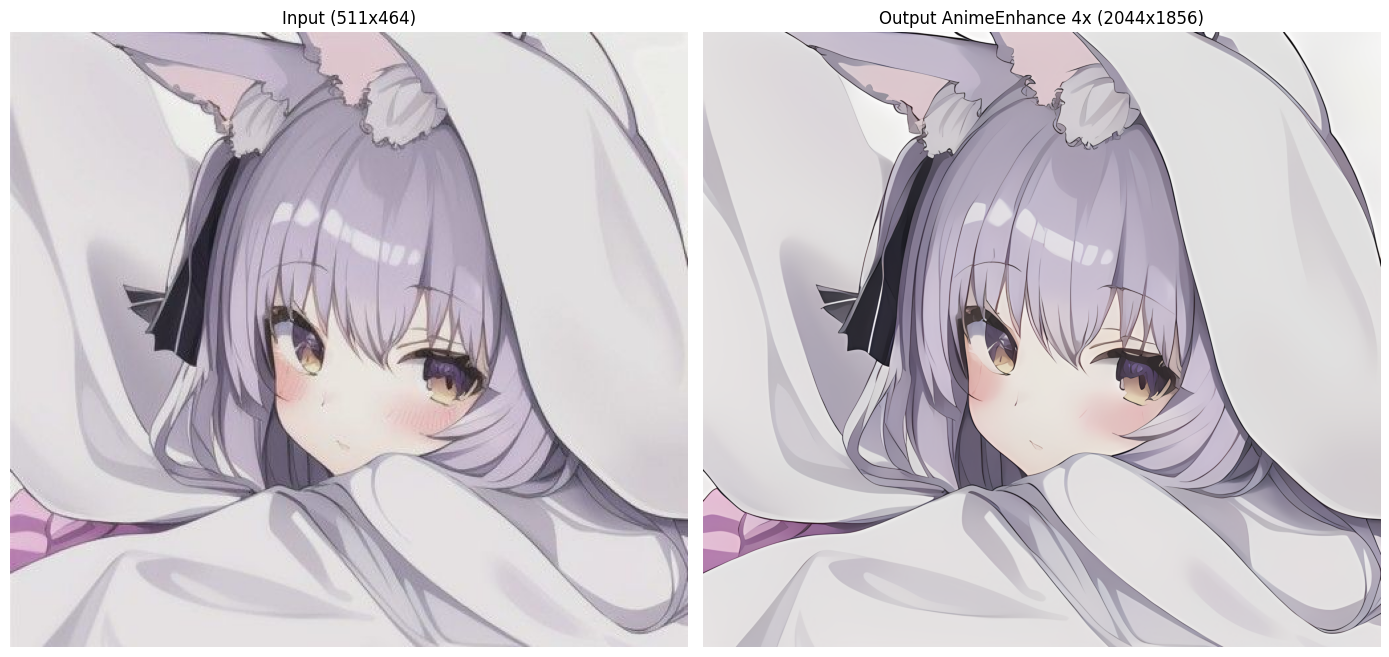

[VISUALIZATION] status=DISPLAYED | mode=full_side_by_side | input=511x464 | output=2044x1856


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(PIL_INPUT_IMAGE)
axes[0].set_title(f"Input ({PIL_INPUT_IMAGE.size[0]}x{PIL_INPUT_IMAGE.size[1]})")
axes[0].axis("off")

axes[1].imshow(FINAL_IMAGE)
axes[1].set_title(f"Output AnimeEnhance 4x ({FINAL_IMAGE.size[0]}x{FINAL_IMAGE.size[1]})")
axes[1].axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)
log_kv(
    "VISUALIZATION",
    status="DISPLAYED",
    mode="full_side_by_side",
    input=f"{PIL_INPUT_IMAGE.size[0]}x{PIL_INPUT_IMAGE.size[1]}",
    output=f"{FINAL_IMAGE.size[0]}x{FINAL_IMAGE.size[1]}",
)

### **9.2 Detail Karakter**

Memotong area tengah sebesar 35% (*Focal ROI*) untuk menginspeksi ketajaman garis *line art* dan detail karakter anime secara mendalam.

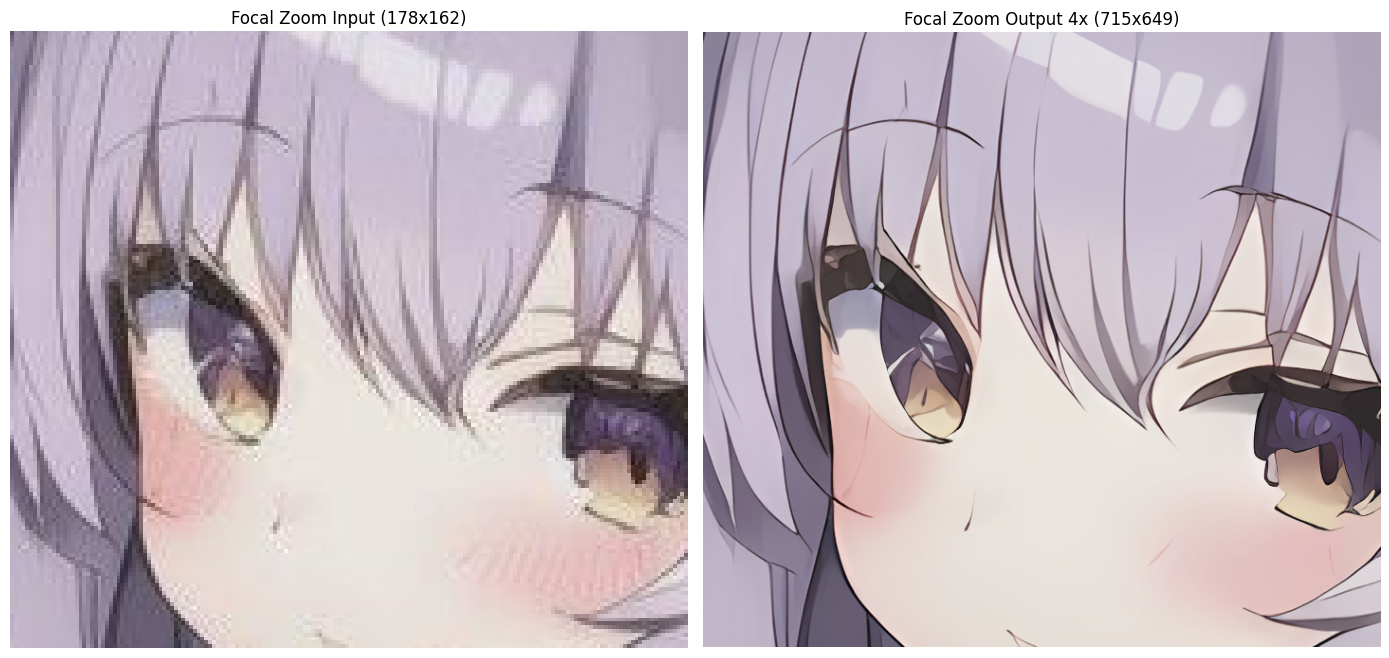

[VISUALIZATION] status=DISPLAYED | mode=focal_center_zoom_35% | crop_in=178x162 | crop_out=715x649


In [22]:
w_in, h_in = PIL_INPUT_IMAGE.size
w_out, h_out = FINAL_IMAGE.size

cw_in, ch_in = int(w_in * 0.35), int(h_in * 0.35)
x1_in, y1_in = (w_in - cw_in) // 2, (h_in - ch_in) // 2
crop_in = PIL_INPUT_IMAGE.crop((x1_in, y1_in, x1_in + cw_in, y1_in + ch_in))

cw_out, ch_out = int(w_out * 0.35), int(h_out * 0.35)
x1_out, y1_out = (w_out - cw_out) // 2, (h_out - ch_out) // 2
crop_out = FINAL_IMAGE.crop((x1_out, y1_out, x1_out + cw_out, y1_out + ch_out))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(crop_in)
axes[0].set_title(f"Focal Zoom Input ({cw_in}x{ch_in})")
axes[0].axis("off")

axes[1].imshow(crop_out)
axes[1].set_title(f"Focal Zoom Output 4x ({cw_out}x{ch_out})")
axes[1].axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)
log_kv(
    "VISUALIZATION",
    status="DISPLAYED",
    mode="focal_center_zoom_35%",
    crop_in=f"{cw_in}x{ch_in}",
    crop_out=f"{cw_out}x{ch_out}",
)

## **10. Ekspor Output**

### **10.1 Kelas ArtifactExporter**

Mendefinisikan kelas `ArtifactExporter` untuk menangani penyimpanan citra PNG 4x *lossless*, verifikasi pasca-tulis (*read-after-write*), penghitungan hash SHA-256, dan pembuatan manifes metadata JSON.

In [23]:
class ArtifactExporter:
    def __init__(self, output_dir: Path):
        self.output_dir = output_dir
        self.output_dir.mkdir(parents=True, exist_ok=True)

    def export_image(self, image: Image.Image, base_stem: str, run_id: str) -> Tuple[Path, str]:
        short_id = run_id[:8]
        out_filename = f"{base_stem}_x4_{short_id}.png"
        out_path = self.output_dir / out_filename
        image.save(out_path, format="PNG", compress_level=1)

        with Image.open(out_path) as verified:
            verified.verify()

        hasher = hashlib.sha256()
        with open(out_path, "rb") as f:
            for chunk in iter(lambda: f.read(65536), b""):
                hasher.update(chunk)
        checksum = hasher.hexdigest()

        return out_path, checksum

    def export_manifest(
        self,
        telemetry: InferenceTelemetry,
        input_meta: ImageMetadata,
        cfg: PipelineConfig,
        ckpt_sha256: str,
        out_path: Path,
        out_sha256: str,
        cuda_ver: str,
        gpu_device: str,
        input_mode: str,
    ) -> Path:
        short_id = telemetry.run_id[:8]
        manifest_data = {
            "run_id": telemetry.run_id,
            "timestamp_utc": telemetry.timestamp,
            "execution_environment": "VS Code Remote - Google Colab (NVIDIA L4 GPU)",
            "input_file": {
                "filename": input_meta.filename,
                "sha256": input_meta.sha256,
                "dimensions": {"width": input_meta.original_size[0], "height": input_meta.original_size[1]},
                "format": input_meta.format,
                "color_mode": input_mode,
            },
            "model_execution": {
                "model_name": cfg.model_name,
                "checkpoint_sha256": ckpt_sha256,
                "scale_factor": cfg.scale,
                "tile_size": cfg.tile_size,
                "tile_padding": cfg.tile_padding,
                "precision": cfg.precision.upper(),
            },
            "environment": {
                "python_version": sys.version.split()[0],
                "torch_version": torch.__version__,
                "cuda_version": cuda_ver,
                "gpu_device": gpu_device,
                "peak_vram_allocated_mb": telemetry.peak_vram_allocated_mb,
                "peak_vram_reserved_mb": telemetry.peak_vram_reserved_mb,
            },
            "output_file": {
                "filename": out_path.name,
                "sha256": out_sha256,
                "dimensions": {"width": input_meta.target_size[0], "height": input_meta.target_size[1]},
                "format": "PNG",
                "execution_duration_seconds": telemetry.duration_seconds,
                "status": telemetry.status,
            },
            "disclaimer": "Detail hasil restorasi merupakan aproksimasi inferensi spasial model, bukan pemulihan ground-truth autentik.",
        }
        manifest_path = self.output_dir / f"manifest_{short_id}.json"
        with open(manifest_path, "w", encoding="utf-8") as f:
            json.dump(manifest_data, f, indent=2)

        return manifest_path

### **10.2 Simpan Output**

Mengekspor citra hasil restorasi ke direktori `data/output/`, memvalidasi integritas berkas via Pillow, dan menyimpan berkas manifes metadata `JSON`.

In [24]:
exporter = ArtifactExporter(PROJECT_ROOT / "data" / "output")
SAVED_IMAGE_PATH, OUTPUT_CHECKSUM = exporter.export_image(
    FINAL_IMAGE,
    Path(INPUT_METADATA.filename).stem,
    TELEMETRY_RECORD.run_id,
)
output_file_mb = round(SAVED_IMAGE_PATH.stat().st_size / (1024 * 1024), 2)
log_kv(
    "EXPORT",
    status="SUCCESS",
    file=SAVED_IMAGE_PATH.name,
    size=f"{output_file_mb}MB",
    verified=True,
    sha256=OUTPUT_CHECKSUM[:16],
)

MANIFEST_PATH = exporter.export_manifest(
    telemetry=TELEMETRY_RECORD,
    input_meta=INPUT_METADATA,
    cfg=CFG,
    ckpt_sha256=CHECKPOINT_SHA256,
    out_path=SAVED_IMAGE_PATH,
    out_sha256=OUTPUT_CHECKSUM,
    cuda_ver=CUDA_VERSION,
    gpu_device=DEVICE_NAME,
    input_mode=PIL_INPUT_IMAGE.mode,
)
log_kv("MANIFEST", status="SAVED", file=MANIFEST_PATH.name)

[EXPORT] status=SUCCESS | file=sample_anime_portrait_x4_cc83570f.png | size=2.48MB | verified=True | sha256=e242a7213bc23871
[MANIFEST] status=SAVED | file=manifest_cc83570f.json


## **11. Pembersihan Memori**

### **11.1 Ringkasan Eksekusi**

Menampilkan ringkasan metrik eksekusi mencakup status proses, durasi inferensi, konsumsi puncak VRAM GPU, dan berkas gambar serta manifes JSON yang dihasilkan.

In [25]:
short_id = TELEMETRY_RECORD.run_id[:8]
log_kv("SUMMARY", status=TELEMETRY_RECORD.status, run_id=short_id)
log_kv(
    "PERFORMANCE",
    duration=f"{TELEMETRY_RECORD.duration_seconds}s",
    peak_vram=f"{TELEMETRY_RECORD.peak_vram_allocated_mb}MB",
    reserved_vram=f"{TELEMETRY_RECORD.peak_vram_reserved_mb}MB",
)
log_kv("ARTIFACTS", output=SAVED_IMAGE_PATH.name, manifest=MANIFEST_PATH.name)

[SUMMARY] status=SUCCESS | run_id=cc83570f
[PERFORMANCE] duration=1.432s | peak_vram=2031.12MB | reserved_vram=2698.0MB
[ARTIFACTS] output=sample_anime_portrait_x4_cc83570f.png | manifest=manifest_cc83570f.json


### **11.2 Pembersihan Cache**

Mengosongkan alokasi cache PyTorch CUDA (`torch.cuda.empty_cache()`) dan menjalankan *garbage collection* (`gc.collect()`) untuk memulihkan VRAM.

In [26]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

remaining_vram_mb = round(torch.cuda.memory_allocated() / (1024 * 1024), 2) if torch.cuda.is_available() else 0.0
log_kv("CLEANUP", status="COMPLETED", cache_cleared=True, remaining_vram=f"{remaining_vram_mb}MB")

[CLEANUP] status=COMPLETED | cache_cleared=True | remaining_vram=8.56MB
